# ECON 5200 Final Project: Consulting Report

**A causal question a client would pay to have answered, a design you can defend under attack, a tool that lets them
explore counterfactuals, and a recommendation with its uncertainty attached.**

This notebook is the spine of the project. Each milestone hands in part of it:

| Hand-in | Due | Parts |
|---|---|---|
| Milestone 1: Proposal + EDA (10 pts) | Mon 23 Nov | Part 2, plus the two-page proposal from the **Proposal Template (Word)** |
| Milestone 2: Analysis + Threats (20 pts) | Thu 3 Dec | Part 3, a first draft of Part 4, a Part 5 prototype with one working what-if input |
| Final Project (70 pts) | see Canvas | all of it, with Part 1 written last |

Every number in your report must be printed by a cell in this notebook. If the code does not print it, the report
cannot use it.

---

## Part 0: Setup

In [10]:
# Colab has pandas, numpy, statsmodels, scikit-learn and matplotlib already.
# Install only what your design needs, then restart the runtime once:
# !pip -q install linearmodels        # IV (2SLS) and panel fixed effects
# !pip -q install rdrobust rddensity   # RD
# !pip -q install doubleml             # DML

In [11]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

RANDOM_STATE = 42                    # every split, fold and bootstrap uses this seed
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (9, 5)
print("Setup complete.")

Setup complete.


---
## Part 1: Executive Summary

Write this **last**. Situation, Complication, Resolution, then the recommendation with its interval and the
assumption it rests on. The rubric looks for all three in the summary itself.

> **We estimate that [treatment] changes [outcome] by [X] [units] (95% CI [a, b]).**
>
> **Situation:** ___
> **Complication:** ___
> **Resolution:** ___
>
> **We recommend [action] because [reason]. At the bottom of the interval, [what the client should still do].**
>
> **The assumption that would overturn this:** ___

---
## Part 2: The Decision, the Design, and the Data (Milestone 1)

### Research design

These lines are the proposal's page 1. The **Proposal Template (Word)** on Canvas has the same headings.

- **Client and decision:** who acts on the answer, and what they will do differently.
- **Decides it:** the effect size at which the decision changes. Write it before you estimate anything.
- **Causal question:** does [treatment] cause [outcome], for whom, by how much?
- **Why prediction is not enough:** the comparison in your data that would mislead the client.
- **Design and estimand:** DiD, IV, RD or DML, and whose effect it recovers (average, on the treated, compliers,
  at the cutoff). DML is Topic 24, taught Wed 9 Dec, after both milestones.
- **Who is treated:** the unit of treatment, and how many treated units your data have.
- **The comparison:** treated against what.
- **Key assumption:** parallel trends / exclusion and relevance / no manipulation at the cutoff / conditional
  independence given these controls.
- **How you will check it:** the test that could fail.
- **The threat you worry about most:** which variable, through which path, and the sign of the bias it would cause.

In [12]:
%pip -q install python-calamine

import pandas as pd

url = "https://www2.census.gov/programs-surveys/demo/tables/health-insurance/time-series/acs/hic04_acs.xlsx"

file = pd.ExcelFile(url, engine="calamine")

print("Sheets:", file.sheet_names)

preview = pd.read_excel(
    file,
    sheet_name=0,
    header=None,
    engine="calamine"
)

display(preview.head(15))


Sheets: ['hic04_acs']


,0,1,2,3,4,5,6,7,8,9,...,64,65,66,67,68,69,70,71,72,73
0,Table with row headers in columns A and B and ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Table HIC-4_ACS. Health Insurance Coverage Sta...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Universe: Civilian noninstitutionalized popula...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,(Numbers in thousands),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Nation/State,Coverage,2025 1,NaN,NaN,NaN,2024,NaN,NaN,NaN,...,NaN,NaN,2009,NaN,NaN,NaN,2008,NaN,NaN,NaN
5,NaN,NaN,Estimate,Margin of error 2,Percent,Margin of error 2,Estimate,Margin of error 2,Percent,Margin of error 2,...,Percent,Margin of error 2,Estimate,Margin of error 2,Percent,Margin of error 2,Estimate,Margin of error 2,Percent,Margin of error 2
6,United States,Total,336800,21,100,0,335200,21,100,0,...,100,0,301500,23,100,0,298600,20,100,0
7,United States,.Any coverage,308500,192,91.6,0.1,307700,221,91.8,0.1,...,84.5,0.1,255800,235,84.9,0.1,255100,230,85.4,0.1
8,United States,.Uninsured,28320,194,8.4,0.1,27480,219,8.2,0.1,...,15.5,0.1,45670,238,15.1,0.1,43500,233,14.6,0.1
9,United States,.Private,213200,473,63.3,0.1,225200,467,67.2,0.1,...,65.8,0.1,203300,379,67.4,0.1,207800,353,69.6,0.1


In [13]:
# Extract state uninsured rates from the Census table
raw = preview.copy()

years = pd.to_numeric(raw.iloc[4], errors="coerce").ffill()
measures = raw.iloc[5].astype(str).str.strip()

# Find the percent column for each year
year_columns = {
    int(years[col]): col
    for col in raw.columns
    if pd.notna(years[col])
    and measures[col].lower() == "percent"
    and 2010 <= years[col] <= 2016
}

print("Years found:", sorted(year_columns))

# Keep the uninsured rows for each state
data = raw.iloc[6:].copy()
data[0] = data[0].ffill()

uninsured = data[
    data[1].astype(str).str.strip().str.lower()
    .str.contains("uninsured", na=False)
].copy()

records = []

for year, col in sorted(year_columns.items()):
    part = pd.DataFrame({
        "state_name": uninsured[0].astype(str).str.strip(),
        "year": year,
        "uninsured_rate": pd.to_numeric(
            uninsured[col], errors="coerce"
        )
    })
    records.append(part)

df = pd.concat(records, ignore_index=True)
df = df.dropna(subset=["uninsured_rate"])

print("Observations:", len(df))
print("States/areas:", df["state_name"].nunique())
display(df.head(10))


Years found: [2010, 2011, 2012, 2013, 2014, 2015, 2016]
Observations: 364
States/areas: 52


,state_name,year,uninsured_rate
0,United States,2010,15.5
1,Alabama,2010,14.6
2,Alaska,2010,19.9
3,Arizona,2010,16.9
4,Arkansas,2010,17.5
5,California,2010,18.5
6,Colorado,2010,15.9
7,Connecticut,2010,9.1
8,Delaware,2010,9.7
9,District of Columbia,2010,7.6


Observations: 308
States/areas: 44
Treated: 25
Comparison: 19

TABLE 1: BEFORE MEDICAID EXPANSION


,Group,Average uninsured rate (%),Number of states/areas
0,Expansion,12.32,25
1,Comparison,15.13,19


Pre-policy difference: -2.81 percentage points


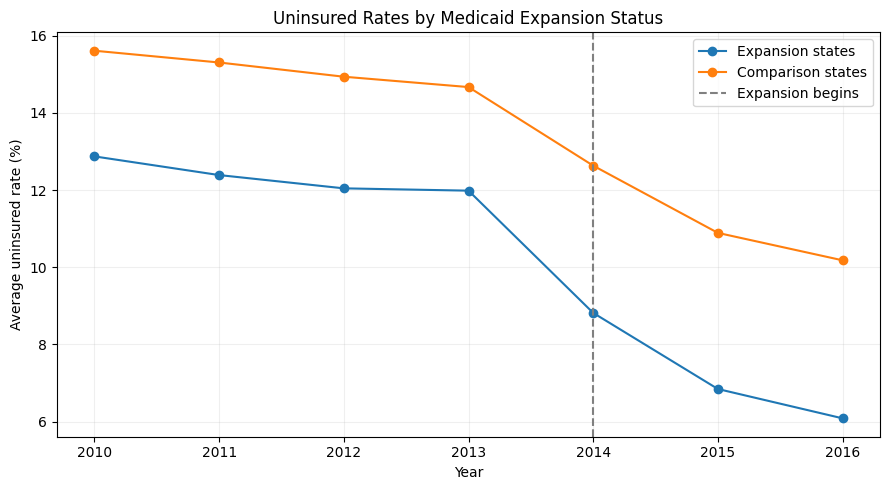


Initial DiD comparison: -1.177 percentage points
Saved: medicaid_eda_data.csv


In [14]:
# Medicaid expansion groups
treated_names = {
    "Arizona", "Arkansas", "California", "Colorado",
    "Connecticut", "Delaware", "District of Columbia",
    "Hawaii", "Illinois", "Iowa", "Kentucky",
    "Maryland", "Massachusetts", "Minnesota",
    "Nevada", "New Jersey", "New Mexico", "New York",
    "North Dakota", "Ohio", "Oregon", "Rhode Island",
    "Vermont", "Washington", "West Virginia"
}

comparison_names = {
    "Alabama", "Florida", "Georgia", "Idaho",
    "Kansas", "Maine", "Mississippi", "Missouri",
    "Nebraska", "North Carolina", "Oklahoma",
    "South Carolina", "South Dakota", "Tennessee",
    "Texas", "Utah", "Virginia", "Wisconsin", "Wyoming"
}

# Keep only the states in our study
df = df[df["state_name"].isin(
    treated_names | comparison_names
)].copy()

df["treated"] = df["state_name"].isin(treated_names).astype(int)
df["post"] = (df["year"] >= 2014).astype(int)
df["treated_post"] = df["treated"] * df["post"]

print("Observations:", len(df))
print("States/areas:", df["state_name"].nunique())
print("Treated:", df[df.treated == 1]["state_name"].nunique())
print("Comparison:", df[df.treated == 0]["state_name"].nunique())

# Table 1: Average uninsured rates before 2014
pre = df[df["year"] < 2014]

means = pre.groupby("treated")["uninsured_rate"].mean()
counts = pre.groupby("treated")["state_name"].nunique()

table1 = pd.DataFrame({
    "Group": ["Expansion", "Comparison"],
    "Average uninsured rate (%)": [
        round(means[1], 2),
        round(means[0], 2)
    ],
    "Number of states/areas": [
        counts[1], counts[0]
    ]
})

print("\nTABLE 1: BEFORE MEDICAID EXPANSION")
display(table1)

print(
    "Pre-policy difference:",
    round(means[1] - means[0], 2),
    "percentage points"
)

# Figure 1: Uninsured rates over time
trends = df.groupby(
    ["year", "treated"]
)["uninsured_rate"].mean().unstack()

plt.figure(figsize=(9, 5))
plt.plot(
    trends.index, trends[1],
    marker="o", label="Expansion states"
)
plt.plot(
    trends.index, trends[0],
    marker="o", label="Comparison states"
)

plt.axvline(
    2014, color="gray",
    linestyle="--", label="Expansion begins"
)

plt.title("Uninsured Rates by Medicaid Expansion Status")
plt.xlabel("Year")
plt.ylabel("Average uninsured rate (%)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("medicaid_trends.png", dpi=200)
plt.show()

# Initial descriptive comparison
before = df[df.year < 2014].groupby(
    "treated"
)["uninsured_rate"].mean()

after = df[df.year >= 2014].groupby(
    "treated"
)["uninsured_rate"].mean()

raw_did = (
    (after[1] - before[1])
    - (after[0] - before[0])
)

print(
    "\nInitial DiD comparison:",
    round(raw_did, 3),
    "percentage points"
)

# Save the final EDA dataset
df.to_csv("medicaid_eda_data.csv", index=False)
print("Saved: medicaid_eda_data.csv")


In [15]:
print("Missing values:")
print(df.isna().sum())

print("\nFinal sample:")
print("Observations:", len(df))
print("States/areas:", df["state_name"].nunique())

print("\nSample rule:")
print("Keep expansion and comparison states with available uninsured-rate data from 2010 to 2016.")

Missing values:
state_name        0
year              0
uninsured_rate    0
treated           0
post              0
treated_post      0
dtype: int64

Final sample:
Observations: 308
States/areas: 44

Sample rule:
Keep expansion and comparison states with available uninsured-rate data from 2010 to 2016.


In [16]:
def balance_table(data, group, cols):
    """Means by group, the difference, and the standardised difference (difference / pooled SD).

    group: a 0/1 column. For RD pass the rows inside your bandwidth, grouped by side of the cutoff;
    for DiD, the pre-period rows grouped by treated state; for IV, grouped by the instrument.
    A standardised difference above about 0.1 in absolute value is worth a sentence in the proposal.
    """
    g1, g0 = data[data[group] == 1], data[data[group] == 0]
    rows = []
    for c in cols:
        sd = np.sqrt((g1[c].var() + g0[c].var()) / 2)
        rows.append({"variable": c, "treated": g1[c].mean(), "comparison": g0[c].mean(),
                     "difference": g1[c].mean() - g0[c].mean(),
                     "std. difference": (g1[c].mean() - g0[c].mean()) / sd if sd > 0 else np.nan})
    out = pd.DataFrame(rows).set_index("variable")
    out.loc["N"] = [len(g1), len(g0), np.nan, np.nan]
    return out.round(3)


balance_table(
    df[df["year"] < 2014],
    "treated",
    ["uninsured_rate"]
)

,treated,comparison,difference,std. difference
variable,,,,
uninsured_rate,12.322,15.13,-2.808,-0.714
N,100.000,76.00,NaN,NaN


In [17]:
# --- Figure 1: the relationship your design is built on ---
# DiD: mean outcome by period for each group, a vertical line at the treatment date
#   df.groupby(["period", "treated"])["outcome"].mean().unstack().plot(marker="o")
# RD: binned means of the outcome against the running variable, a vertical line at the cutoff
#   bins = pd.cut(df["running"], 40); df.groupby(bins, observed=True)["outcome"].mean().plot(style="o")
# IV: the first stage, treatment rate by value of the instrument
#   df.groupby("instrument")["treatment"].mean().plot(kind="bar")
# plt.title("..."); plt.xlabel("..."); plt.ylabel("..."); plt.show()

**Key EDA finding (one sentence, with a number this notebook printed):** My initial DiD comparison is −1.177 percentage points. Uninsured rates fell more in expansion states after 2014.

**A concern the design will have to handle:** Expansion states already had lower uninsured rates before 2014. Other health insurance changes may also explain part of the difference.

---
## Part 3: Analysis (Milestone 2)

### 3a. The naive estimate

The comparison a client's own analyst would run first. You expect it to be biased; say which way, and why.

In [18]:
# naive = smf.ols("outcome ~ treatment", data=df).fit(cov_type="HC1")
# print(naive.params["treatment"], naive.bse["treatment"])

**Why the naive estimate is biased, and in which direction:** ___

### 3b. The causal estimate

Keep the one cell that matches your design and delete the other three. Each reports the estimate, its standard
error and the diagnostic its design must pass.

In [19]:
# --- DiD: two-way fixed effects, standard errors clustered by the unit that was treated ---
# did = smf.ols("outcome ~ treated_post + C(unit) + C(period)", data=df).fit(
#     cov_type="cluster", cov_kwds={"groups": df["unit"]})
# est, se = did.params["treated_post"], did.bse["treated_post"]
#
# Diagnostic, an event study: one coefficient per period relative to treatment, the period before omitted.
# Pre-period coefficients near zero support parallel trends; they cannot prove it.
# es = smf.ols("outcome ~ C(rel_time, Treatment(reference=-1)) + C(unit) + C(period)", data=df).fit(
#     cov_type="cluster", cov_kwds={"groups": df["unit"]})
# With few treated clusters (under about 20), say so and report a wild cluster bootstrap p-value as well.

In [20]:
# --- IV: two-stage least squares, with the first stage reported ---
# from linearmodels.iv import IV2SLS
# iv = IV2SLS.from_formula("outcome ~ 1 + control_1 + [treatment ~ instrument]", data=df).fit(cov_type="robust")
# est, se = iv.params["treatment"], iv.std_errors["treatment"]
# print(iv.first_stage)          # the first-stage F: below 10 is weak, and the 2SLS interval cannot be trusted
# The estimate is the effect for compliers, the units the instrument moved: say who they are.

In [21]:
# --- RD: local linear, the bandwidth chosen by rdrobust, the effect at the cutoff ---
# from rdrobust import rdrobust
# from rddensity import rddensity
# rd = rdrobust(y=df["outcome"], x=df["running"], c=CUTOFF)
# est, se = rd.coef.loc["Conventional", "Coeff"], rd.se.loc["Conventional", "Std. Err."]
# print(rd)                      # report the bandwidth with the estimate
# print(rd.ci.loc["Robust"])     # the bias-corrected interval: report this one, beside est
# print(rddensity(X=df["running"].to_numpy(), c=CUTOFF).test)   # manipulation at the cutoff
# rdrobust reports right minus left: if treatment is BELOW the cutoff, use running = CUTOFF - x.

In [22]:
# --- DML: partially linear model, cross-fitted, five folds (Topic 24, taught Wed 9 Dec: read Chapter 24 ahead) ---
# from doubleml import DoubleMLData, DoubleMLPLR
# from sklearn.ensemble import RandomForestRegressor
# controls = ["control_1", "control_2", "control_3"]
# dml_data = DoubleMLData(df, y_col="outcome", d_cols="treatment", x_cols=controls)
# learner = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE)
# dml = DoubleMLPLR(dml_data, ml_l=learner, ml_m=learner, n_folds=5)
# dml.fit()
# est, se = dml.coef[0], dml.se[0]
# Diagnostic: overlap. If some units are almost certainly treated or untreated given the controls, the
# estimate leans on extrapolation; plot the cross-fitted treatment predictions by treatment group.

In [23]:
# --- The estimate, its interval and N, in one line the report can quote ---
# ci_low, ci_high = est - 1.96 * se, est + 1.96 * se
# print(f"estimate {est:+.4f} (SE {se:.4f}), 95% CI [{ci_low:+.4f}, {ci_high:+.4f}], N = {len(df):,}")

### 3c. Naive against causal

> The naive estimate is [X]; the causal estimate is [Y]. The gap of [Y - X] is what [the confounder / selection]
> was doing, and its sign matches (or does not match) the direction predicted in 3a.

### 3d. A robustness check that could have overturned the result

The mission asks for at least one check that could have gone the other way. Pick by design:

| Design | A check that can fail |
|---|---|
| DiD | a placebo treatment date in the pre-period; an outcome the policy cannot affect; drop each treated unit in turn |
| IV | a second instrument, alone; the reduced form; an Anderson–Rubin interval if the first stage is weak |
| RD | half and double the bandwidth; a donut that drops the units nearest the cutoff; placebo cutoffs |
| DML | a different learner for the nuisances; a different control set; trimming units with extreme treatment predictions |

For each: what you changed, what you found (the number beside the baseline), and **what it implies** for the claim.

In [24]:
# --- Robustness: your check here ---

### 3e. Sensitivity bound

How strong would an unobserved confounder have to be to erase the estimate, measured against one you observed?
For a regression-based estimate (DiD, DML's final stage, OLS with controls) the **robustness value** answers it
(Cinelli and Hazlett 2020, *JRSS-B* 82(1)). It is the share of the remaining variance of both the treatment and the
outcome that a confounder would have to explain to bring the estimate to zero. Compare it with the strongest control
you have: if no confounder as strong as that control could erase the estimate, say so; if one could, say that.

For RD and IV the equivalent question is about the design's own assumption: how far would the outcome have to jump
at the cutoff for other reasons, or how large a direct effect of the instrument, to explain the estimate?

In [25]:
def robustness_value(t_stat, dof, q=1.0):
    """Cinelli and Hazlett's RV_q: the partial R-squared a confounder needs with BOTH treatment and outcome to
    move the estimate by 100*q percent (q = 1 brings it to zero)."""
    f = q * abs(t_stat) / np.sqrt(dof)
    return 0.5 * (np.sqrt(f**4 + 4 * f**2) - f**2)


def partial_r2(t_stat, dof):
    """A regressor's partial R-squared, recovered from its t-statistic."""
    return t_stat**2 / (t_stat**2 + dof)


# The paper's own example (Darfur, t = 4.18 on 783 degrees of freedom) gives RV = 13.9%:
print(f"check against Cinelli and Hazlett's example: RV = {robustness_value(4.18, 783):.1%} (paper: 13.9%)")

# Your estimate, from a regression with your controls (fit.tvalues / fit.df_resid):
# rv = robustness_value(fit.tvalues["treatment"], fit.df_resid)
# Benchmark: your strongest control's partial R-squared with the outcome, and with the treatment.
# out_fit = smf.ols("outcome ~ treatment + control_1 + control_2", data=df).fit()
# trt_fit = smf.ols("treatment ~ control_1 + control_2", data=df).fit()
# bench_y = partial_r2(out_fit.tvalues["control_1"], out_fit.df_resid)
# bench_d = partial_r2(trt_fit.tvalues["control_1"], trt_fit.df_resid)
# print(f"RV = {rv:.1%}; control_1 explains {bench_y:.1%} of the outcome and {bench_d:.1%} of the treatment")

check against Cinelli and Hazlett's example: RV = 13.9% (paper: 13.9%)


---
## Part 4: Threats to Identification (draft at Milestone 2)

Not "there may be confounding": **which** variable, through **which** path, and **which way** it moves your estimate.
A threat you cannot address is still worth naming. An unnamed one is what the client's analyst will find.

| Threat | Path | Sign of the bias | What I did about it |
|---|---|---|---|
| ___ | ___ → treatment, ___ → outcome | too large / too small / unknown, and why | ___ |
| ___ | ___ | ___ | ___ |
| ___ | ___ | ___ | ___ |

**What I cannot rule out, and what it means for how the client should read the estimate** (an upper bound, a lower
bound, or suggestive only): ___

Milestone 2 asks for at least 500 words across the table and this paragraph.

---
## Part 5: The Streamlit Dashboard

The app must not fit a model. Your deliverable is a causal estimate, a number and a standard error, so write them
to `results.json` here and let the app do arithmetic. The Canvas page **Streamlit Dashboard and Deployment** has
the deployment steps, `requirements.txt`, and every deploy error by its message.

A what-if is an input **the client controls** and an output that is a counterfactual with its interval:
how many units the policy reaches, what it costs, how much hidden bias they are willing to assume. Scaling the
effect beyond the range of treatment in your data is an extrapolation; if your app offers it, the page must say so.

In [26]:
# --- results.json: everything the app needs, printed by this notebook ---
# results = {
#     "question": "Does [treatment] change [outcome]?",
#     "design": "DiD", "estimand": "effect on the treated",
#     "estimate": float(est), "se": float(se), "n": int(len(df)),
#     "unit": "[outcome units] per [treated unit]",
#     "baseline": float(df.loc[df["treatment"] == 0, "outcome"].mean()),   # continuous treatment: df["outcome"].mean()
#     "robustness_value": float(rv),
# }
# with open("results.json", "w") as f:
#     json.dump(results, f, indent=1)
# print(json.dumps(results, indent=1))

In [27]:
app_py = """
import json

import numpy as np
import plotly.graph_objects as go
import streamlit as st

r = json.load(open("results.json"))
st.set_page_config(page_title="Consulting Report", layout="wide")
st.title(r["question"])
st.caption(f"{r['design']}, {r['estimand']}, N = {r['n']:,}")

st.sidebar.header("Your scenario")
reach = st.sidebar.number_input("Units the policy would reach", min_value=1, value=100, step=10)
cost = st.sidebar.number_input("Cost per unit reached", min_value=0.0, value=0.0, step=1.0)
bias = st.sidebar.slider("Hidden bias you are willing to assume (share of the estimate)", -1.0, 1.0, 0.0, 0.05,
                         help="0 trusts the design. 0.5 assumes half the estimate is confounding.")

est = r["estimate"] * (1 - bias)
se = r["se"]
total, total_lo, total_hi = est * reach, (est - 1.96 * se) * reach, (est + 1.96 * se) * reach

c1, c2, c3 = st.columns(3)
c1.metric("Effect per unit", f"{est:+.3f}", help=r["unit"])
c2.metric("Total effect, 95% CI", f"{total:+,.1f}", f"[{total_lo:+,.1f}, {total_hi:+,.1f}]", delta_color="off")
c3.metric("Total cost", f"{cost * reach:,.0f}")

st.markdown(f"If the policy reaches **{reach:,}** units, the estimated total change is **{total:+,.1f}** "
            f"(95% CI {total_lo:+,.1f} to {total_hi:+,.1f}), assuming {bias:.0%} of the estimate is hidden bias.")

grid = np.linspace(-1, 1, 81)
mid = r["estimate"] * (1 - grid)
fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=mid + 1.96 * se, mode="lines", line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=grid, y=mid - 1.96 * se, mode="lines", line=dict(width=0), fill="tonexty",
                         fillcolor="rgba(46,109,180,0.2)", name="95% CI"))
fig.add_trace(go.Scatter(x=grid, y=mid, mode="lines", line=dict(color="#2E6DB4"), name="Effect per unit"))
fig.add_hline(y=0, line_dash="dot", line_color="grey")
fig.add_vline(x=bias, line_dash="dash", line_color="#b03a2e")
fig.update_layout(xaxis_title="Assumed hidden bias (share of the estimate)", yaxis_title=r["unit"],
                  template="plotly_white")
st.plotly_chart(fig)
"""

# Uncomment to write it, then commit app.py, results.json and requirements.txt to your repository:
# with open("app.py", "w") as f:
#     f.write(app_py)
print("app.py template ready: uncomment the two lines above to write it.")

app.py template ready: uncomment the two lines above to write it.


**The `.py` module.** The repository needs a module, not only notebooks. Move the functions you call more than once
(loading and cleaning, the estimate, the robustness check) into `src/analysis.py`, import them here, and let the
README name the one command that reproduces `results.json`.

---
## Part 6: The Five-Minute Video

Exactly three things. Five minutes is a ceiling, not a target.

| | What it is | Yours |
|---|---|---|
| **One visual** | the figure that makes the causal claim believable (Figure 1 or the event study, usually) | ___ |
| **One causal claim** | the estimate, its unit and interval, and the assumption under it, in one sentence | ___ |
| **One recommendation** | what the client should do, and what they should still do at the bottom of the interval | ___ |

### Prepare for the public Q&A

Classmates will open GitHub Issues on your repository. Write your answers to these before they ask:

| They will ask | Your answer |
|---|---|
| "How do you know this is causal?" | ___ |
| "What is the strongest threat, and which way does it bias you?" | ___ |
| "Would this hold for a different population or time?" | ___ |
| "Is the effect big enough to act on?" | ___ |

---
## Part 7: AI Methodology Appendix (P.R.I.M.E.)

At least three entries, each through the five steps: **P**rep, **R**equest, **I**terate, **M**echanism Check,
**E**valuate. Hand it in as a PDF with the report.

### Entry 1: [task]

- **Prep:** what you needed, and what you knew before you asked
- **Request:** the exact prompt
- **Iterate:** what came back, and what you changed or asked again
- **Mechanism Check:** how you verified it: a test you ran, a number you reproduced, a source you checked
- **Evaluate:** what you accepted, what you rejected, and why

### Entry 2: [task]

- **Prep:** ___
- **Request:** ___
- **Iterate:** ___
- **Mechanism Check:** ___
- **Evaluate:** ___

### Entry 3: [task]

- **Prep:** ___
- **Request:** ___
- **Iterate:** ___
- **Mechanism Check:** ___
- **Evaluate:** ___

> Graded on judgment, not volume. One entry where the model was wrong and you caught it at the Mechanism Check is
> worth more than three where you pasted and moved on.